<a href="https://colab.research.google.com/github/sanjil18/CNN-project/blob/main/CNN_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import os
import time
import shutil
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

project_path = '/content/drive/MyDrive/CNN-project'
zip_path = f'{project_path}/intel-image-classification.zip'
data_dir = '/content/intel_data'
train_dir = f'{data_dir}/seg_train/seg_train'
val_dir = f'{data_dir}/seg_val'
test_dir = f'{data_dir}/seg_test/seg_test'

os.makedirs(project_path, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [21]:
if os.path.exists(data_dir):
    print('Dataset ஏற்கனவே local-ல இருக்கு')
elif os.path.exists(zip_path):
    !unzip -q "{zip_path}" -d "{data_dir}"
    print('Dataset local-ல extract ஆயிடுச்சு')
else:
    print('Zip file Drive-ல இல்ல, Kaggle-ல இருந்து download பண்ணணும்')

Dataset local-ல extract ஆயிடுச்சு


In [22]:
already_split = os.path.exists(val_dir) and len(os.listdir(val_dir)) > 0

if already_split:
    print('Split ஏற்கனவே முடிஞ்சிருக்கு, skip பண்றோம்')
else:
    os.makedirs(val_dir, exist_ok=True)
    for cls in sorted(os.listdir(train_dir)):
        cls_path = os.path.join(train_dir, cls)
        images = sorted(os.listdir(cls_path))
        _, val_images = train_test_split(images, test_size=0.15, random_state=42)

        val_cls_dir = os.path.join(val_dir, cls)
        os.makedirs(val_cls_dir, exist_ok=True)

        for img_name in val_images:
            shutil.move(os.path.join(cls_path, img_name),
                        os.path.join(val_cls_dir, img_name))
        print(f'{cls}: moved {len(val_images)} images to val')

buildings: moved 329 images to val
forest: moved 341 images to val
glacier: moved 361 images to val
mountain: moved 377 images to val
sea: moved 342 images to val
street: moved 358 images to val


In [23]:
for name, path in [('train', train_dir), ('val', val_dir), ('test', test_dir)]:
    print(name)
    total = 0
    for cls in sorted(os.listdir(path)):
        n = len(os.listdir(os.path.join(path, cls)))
        total += n
        print('  ', cls, n)
    print('  total:', total)

train
   buildings 1862
   forest 1930
   glacier 2043
   mountain 2135
   sea 1932
   street 2024
  total: 11926
val
   buildings 329
   forest 341
   glacier 361
   mountain 377
   sea 342
   street 358
  total: 2108
test
   buildings 437
   forest 474
   glacier 553
   mountain 525
   sea 510
   street 501
  total: 3000


In [24]:
transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_ds = datasets.ImageFolder(train_dir, transform=transform)
val_ds   = datasets.ImageFolder(val_dir, transform=transform)
test_ds  = datasets.ImageFolder(test_dir, transform=transform)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2)

print(train_ds.transform)
print(train_ds.class_to_idx)
print(len(train_ds), len(val_ds), len(test_ds))

Compose(
    Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)
{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}
11926 2108 3000


In [25]:
bad = 0
for images, labels in train_loader:
    if images.shape[1:] != (3, 150, 150):
        bad += 1
print('Bad batches:', bad)

Bad batches: 0


In [26]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 18 * 18, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = SimpleCNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

print('Total params:', sum(p.numel() for p in model.parameters()))

Total params: 10711878


In [27]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

In [28]:
EPOCHS = 10
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0.0
save_path = f'{project_path}/best_scratch_cnn.pth'

for epoch in range(EPOCHS):
    start = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(va_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(va_acc)

    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), save_path)
        saved = '  ← best, saved'
    else:
        saved = ''

    print(f'Epoch {epoch+1}/{EPOCHS} | '
          f'train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
          f'val loss {va_loss:.3f} acc {va_acc:.3f} | '
          f'{time.time()-start:.0f}s{saved}')

Epoch 1/10 | train loss 0.968 acc 0.624 | val loss 0.689 acc 0.742 | 19s  ← best, saved
Epoch 2/10 | train loss 0.648 acc 0.765 | val loss 0.593 acc 0.775 | 18s  ← best, saved
Epoch 3/10 | train loss 0.517 acc 0.813 | val loss 0.522 acc 0.801 | 19s  ← best, saved
Epoch 4/10 | train loss 0.416 acc 0.848 | val loss 0.561 acc 0.803 | 19s  ← best, saved
Epoch 5/10 | train loss 0.336 acc 0.882 | val loss 0.577 acc 0.818 | 19s  ← best, saved
Epoch 6/10 | train loss 0.261 acc 0.910 | val loss 0.550 acc 0.823 | 19s  ← best, saved
Epoch 7/10 | train loss 0.199 acc 0.926 | val loss 0.623 acc 0.828 | 18s  ← best, saved
Epoch 8/10 | train loss 0.144 acc 0.949 | val loss 0.680 acc 0.817 | 20s
Epoch 9/10 | train loss 0.120 acc 0.956 | val loss 0.873 acc 0.803 | 18s
Epoch 10/10 | train loss 0.124 acc 0.957 | val loss 0.775 acc 0.819 | 18s


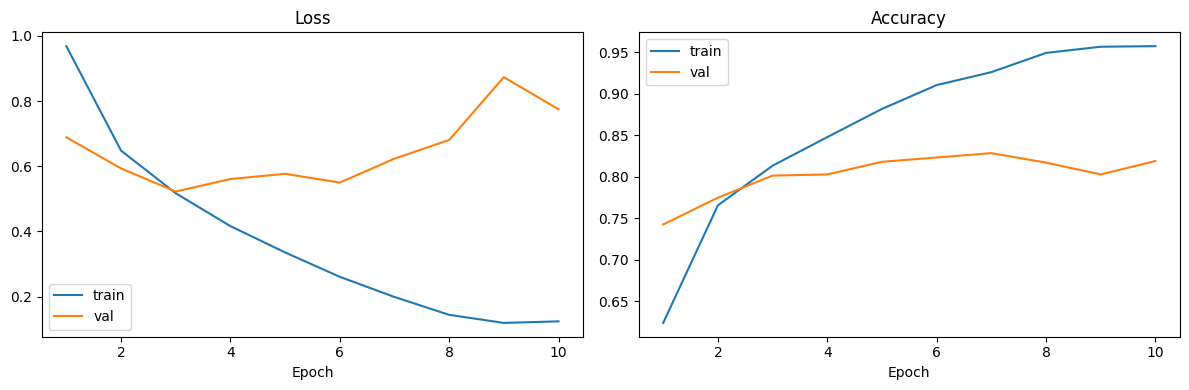

In [29]:
import json
import matplotlib.pyplot as plt

with open(f'{project_path}/history_scratch.json', 'w') as f:
    json.dump(history, f)

epochs = range(1, len(history['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history['train_loss'], label='train')
ax[0].plot(epochs, history['val_loss'], label='val')
ax[0].set_title('Loss')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(epochs, history['train_acc'], label='train')
ax[1].plot(epochs, history['val_acc'], label='val')
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.tight_layout()
plt.savefig(f'{project_path}/scratch_curves.png', dpi=150)
plt.show()

In [30]:
model.load_state_dict(torch.load(save_path, map_location=device))
test_loss, test_acc = run_epoch(test_loader, train=False)
print(f'Test loss {test_loss:.3f} | Test acc {test_acc:.3f}')

Test loss 0.573 | Test acc 0.838


In [31]:
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)

tl_transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

tl_train_ds = datasets.ImageFolder(train_dir, transform=tl_transform)
tl_val_ds   = datasets.ImageFolder(val_dir, transform=tl_transform)
tl_test_ds  = datasets.ImageFolder(test_dir, transform=tl_transform)

tl_train_loader = DataLoader(tl_train_ds, batch_size=32, shuffle=True,  num_workers=2)
tl_val_loader   = DataLoader(tl_val_ds,   batch_size=32, shuffle=False, num_workers=2)
tl_test_loader  = DataLoader(tl_test_ds,  batch_size=32, shuffle=False, num_workers=2)

print(tl_train_ds.transform)
print(len(tl_train_ds), len(tl_val_ds), len(tl_test_ds))

Compose(
    Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)
11926 2108 3000


In [32]:
from torchvision import models

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for p in model.parameters():
    p.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 6)
model = model.to(device)

optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

print('Trainable params:', sum(p.numel() for p in model.parameters() if p.requires_grad))
print('Total params    :', sum(p.numel() for p in model.parameters()))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 130MB/s]


Trainable params: 3078
Total params    : 11179590


In [33]:
def fit(epochs, save_file, history, tag):
    best = max(history['val_acc']) if history['val_acc'] else 0.0
    for epoch in range(epochs):
        start = time.time()
        tr_loss, tr_acc = run_epoch(tl_train_loader, train=True)
        va_loss, va_acc = run_epoch(tl_val_loader, train=False)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)

        if va_acc > best:
            best = va_acc
            torch.save(model.state_dict(), save_file)
            saved = '  ← best, saved'
        else:
            saved = ''

        print(f'[{tag}] Epoch {epoch+1}/{epochs} | '
              f'train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} | '
              f'{time.time()-start:.0f}s{saved}')

tl_history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
tl_save_path = f'{project_path}/best_resnet18.pth'

In [34]:
fit(epochs=3, save_file=tl_save_path, history=tl_history, tag='head only')

[head only] Epoch 1/3 | train loss 0.572 acc 0.806 | val loss 0.342 acc 0.881 | 17s  ← best, saved
[head only] Epoch 2/3 | train loss 0.361 acc 0.873 | val loss 0.312 acc 0.892 | 18s  ← best, saved
[head only] Epoch 3/3 | train loss 0.334 acc 0.880 | val loss 0.315 acc 0.888 | 18s


In [35]:
for p in model.parameters():
    p.requires_grad = True

optimizer = optim.Adam(model.parameters(), lr=0.0001)

fit(epochs=5, save_file=tl_save_path, history=tl_history, tag='fine-tune')

[fine-tune] Epoch 1/5 | train loss 0.292 acc 0.897 | val loss 0.234 acc 0.917 | 27s  ← best, saved
[fine-tune] Epoch 2/5 | train loss 0.104 acc 0.962 | val loss 0.244 acc 0.923 | 26s  ← best, saved
[fine-tune] Epoch 3/5 | train loss 0.054 acc 0.982 | val loss 0.308 acc 0.919 | 26s
[fine-tune] Epoch 4/5 | train loss 0.035 acc 0.989 | val loss 0.302 acc 0.924 | 26s  ← best, saved
[fine-tune] Epoch 5/5 | train loss 0.047 acc 0.985 | val loss 0.324 acc 0.917 | 27s


In [36]:
model.load_state_dict(torch.load(tl_save_path, map_location=device))
tl_test_loss, tl_test_acc = run_epoch(tl_test_loader, train=False)

print(f'ResNet18 test acc : {tl_test_acc:.3f}  (loss {tl_test_loss:.3f})')
print(f'Scratch CNN test acc: 0.838  (loss 0.573)')

with open(f'{project_path}/history_resnet18.json', 'w') as f:
    json.dump(tl_history, f)

ResNet18 test acc : 0.921  (loss 0.274)
Scratch CNN test acc: 0.838  (loss 0.573)


              precision    recall  f1-score   support

   buildings      0.917     0.911     0.914       437
      forest      0.987     0.987     0.987       474
     glacier      0.878     0.872     0.875       553
    mountain      0.897     0.850     0.873       525
         sea      0.934     0.978     0.956       510
      street      0.918     0.938     0.928       501

    accuracy                          0.921      3000
   macro avg      0.922     0.923     0.922      3000
weighted avg      0.921     0.921     0.921      3000



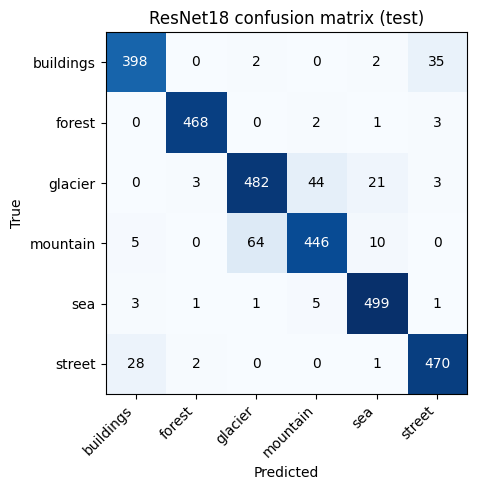

In [37]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in tl_test_loader:
        outputs = model(images.to(device))
        all_preds.extend(outputs.argmax(1).cpu().tolist())
        all_labels.extend(labels.tolist())

class_names = tl_test_ds.classes
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(6))
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_yticks(range(6))
ax.set_yticklabels(class_names)
for i in range(6):
    for j in range(6):
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, cm[i, j], ha='center', va='center', color=color)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('ResNet18 confusion matrix (test)')
plt.tight_layout()
plt.savefig(f'{project_path}/confusion_matrix_resnet18.png', dpi=150)
plt.show()

Misclassified: 237 of 3000


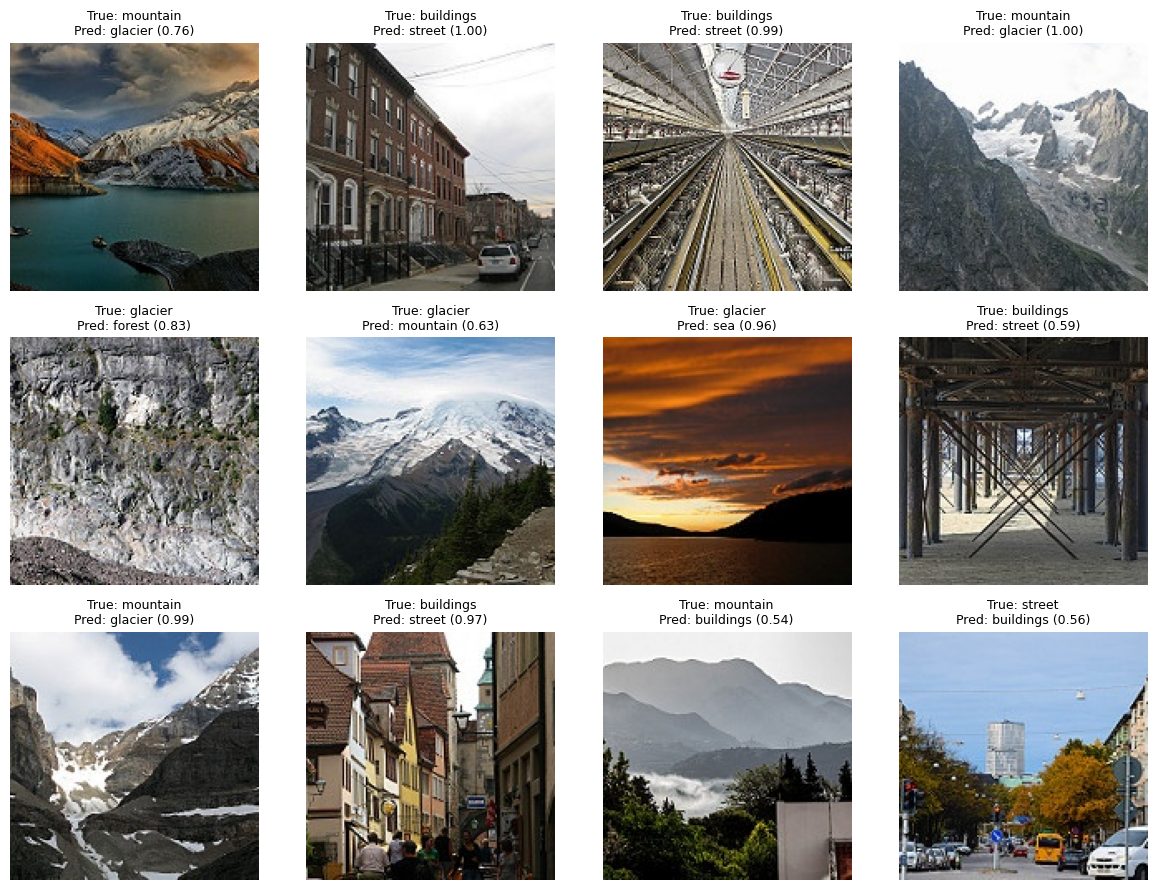

In [38]:
import random

mean = torch.tensor(imagenet_mean).view(3, 1, 1)
std = torch.tensor(imagenet_std).view(3, 1, 1)

wrong = []
with torch.no_grad():
    for images, labels in tl_test_loader:
        probs = model(images.to(device)).softmax(1).cpu()
        preds = probs.argmax(1)
        for img, y, p, pr in zip(images, labels, preds, probs):
            if y != p:
                wrong.append((img, y.item(), p.item(), pr[p].item()))

print('Misclassified:', len(wrong), 'of', len(tl_test_ds))

random.seed(42)
sample = random.sample(wrong, min(12, len(wrong)))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, (img, y, p, conf) in zip(axes.flat, sample):
    img = (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.set_title(f'True: {class_names[y]}\nPred: {class_names[p]} ({conf:.2f})', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{project_path}/misclassified_resnet18.png', dpi=150)
plt.show()

In [39]:
aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(150, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

aug_train_ds = datasets.ImageFolder(train_dir, transform=aug_transform)
aug_train_loader = DataLoader(aug_train_ds, batch_size=32, shuffle=True, num_workers=2)

print(aug_train_ds.transform)
print(len(aug_train_ds))

Compose(
    RandomResizedCrop(size=(150, 150), scale=(0.7, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)
11926


In [40]:
def fit_with(train_loader, val_loader, epochs, save_file, history, tag):
    best = max(history['val_acc']) if history['val_acc'] else 0.0
    for epoch in range(epochs):
        start = time.time()
        tr_loss, tr_acc = run_epoch(train_loader, train=True)
        va_loss, va_acc = run_epoch(val_loader, train=False)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)

        if va_acc > best:
            best = va_acc
            torch.save(model.state_dict(), save_file)
            saved = '  ← best, saved'
        else:
            saved = ''

        print(f'[{tag}] Epoch {epoch+1}/{epochs} | '
              f'train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} | '
              f'{time.time()-start:.0f}s{saved}')

aug_history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
aug_save_path = f'{project_path}/best_resnet18_aug.pth'

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, 6)
model = model.to(device)
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

In [41]:
fit_with(aug_train_loader, tl_val_loader, 3, aug_save_path, aug_history, 'aug head only')

for p in model.parameters():
    p.requires_grad = True
optimizer = optim.Adam(model.parameters(), lr=0.0001)

fit_with(aug_train_loader, tl_val_loader, 5, aug_save_path, aug_history, 'aug fine-tune')

[aug head only] Epoch 1/3 | train loss 0.688 acc 0.766 | val loss 0.396 acc 0.855 | 39s  ← best, saved
[aug head only] Epoch 2/3 | train loss 0.476 acc 0.833 | val loss 0.373 acc 0.866 | 38s  ← best, saved
[aug head only] Epoch 3/3 | train loss 0.443 acc 0.844 | val loss 0.369 acc 0.868 | 38s  ← best, saved
[aug fine-tune] Epoch 1/5 | train loss 0.361 acc 0.876 | val loss 0.265 acc 0.913 | 40s  ← best, saved
[aug fine-tune] Epoch 2/5 | train loss 0.253 acc 0.911 | val loss 0.235 acc 0.919 | 43s  ← best, saved
[aug fine-tune] Epoch 3/5 | train loss 0.207 acc 0.925 | val loss 0.228 acc 0.927 | 42s  ← best, saved
[aug fine-tune] Epoch 4/5 | train loss 0.181 acc 0.936 | val loss 0.230 acc 0.926 | 40s
[aug fine-tune] Epoch 5/5 | train loss 0.158 acc 0.941 | val loss 0.219 acc 0.928 | 41s  ← best, saved


In [42]:
model.load_state_dict(torch.load(aug_save_path, map_location=device))
aug_test_loss, aug_test_acc = run_epoch(tl_test_loader, train=False)

with open(f'{project_path}/history_resnet18_aug.json', 'w') as f:
    json.dump(aug_history, f)

with open(f'{project_path}/history_resnet18.json') as f:
    base_history = json.load(f)

print('Scratch CNN        : test acc 0.838')
print('ResNet18           : test acc 0.921')
print(f'ResNet18 + augment : test acc {aug_test_acc:.3f}  (loss {aug_test_loss:.3f})')
print()
print('Final-epoch train-val gap, no aug :', round(base_history['train_acc'][-1] - base_history['val_acc'][-1], 3))
print('Final-epoch train-val gap, aug    :', round(aug_history['train_acc'][-1] - aug_history['val_acc'][-1], 3))

Scratch CNN        : test acc 0.838
ResNet18           : test acc 0.921
ResNet18 + augment : test acc 0.920  (loss 0.232)

Final-epoch train-val gap, no aug : 0.068
Final-epoch train-val gap, aug    : 0.013
